In [1]:
# %pip install scikit_learn
# %pip install requests

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import *

In [3]:
import torch
from torch import nn # neural network
from torch.optim import Adam # parameter 최적화 알고리즘인 Adam
from torch.utils.data import TensorDataset, DataLoader # 데이터 다루는 도구

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [5]:
# 데이터 불러오기
import requests
from io import BytesIO
import certifi

path = 'https://bit.ly/advertising_csv'
response = requests.get(path,verify=certifi.where(),timeout=15)
response.raise_for_status()
adv = pd.read_csv(BytesIO(response.content))

# x, y 분할
target = 'Sales'
x = adv.drop(target, axis= 1)
y = adv.loc[:, target]

# 학습 / 검증 데이터 분리
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size= .2, random_state=20)

print(type(x_train), type(x_val)) # 판다스 데이터프레임

# 스케일링
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

print(type(x_train), type(x_val)) # numpy ndarray

<class 'pandas.DataFrame'> <class 'pandas.DataFrame'>
<class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [6]:
# 텐서 변환
x_train_ts = torch.as_tensor(x_train, dtype=torch.float32)
y_train_ts = torch.as_tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)

x_val_ts = torch.as_tensor(x_val, dtype=torch.float32)
y_val_ts = torch.as_tensor(y_val.values, dtype=torch.float32).reshape(-1, 1)

# Check tensor dimensions
print("\nTENSORS")
print("x_train_ts:", x_train_ts.shape, x_train_ts.size(0))
print("y_train_ts:", y_train_ts.shape, y_train_ts.size(0))
print("x_val_ts:", x_val_ts.shape, x_val_ts.size(0))
print("y_val_ts:", y_val_ts.shape, y_val_ts.size(0))

# Verify alignment
assert x_train_ts.size(0) == y_train_ts.size(0)
assert x_val_ts.size(0) == y_val_ts.size(0)

# 디바이스 할당
x_train_ts, y_train_ts = x_train_ts.to(device), y_train_ts.to(device)
x_val_ts, y_val_ts = x_val_ts.to(device), y_val_ts.to(device)

# Create datasets
BATCH_SIZE = 32
train_ds = TensorDataset(x_train_ts, y_train_ts)
train_loader = DataLoader(train_ds, batch_size= BATCH_SIZE, shuffle=True)

print("\nSUCCESS")
print("Training samples:", len(train_ds))


TENSORS
x_train_ts: torch.Size([160, 3]) 160
y_train_ts: torch.Size([160, 1]) 160
x_val_ts: torch.Size([40, 3]) 40
y_val_ts: torch.Size([40, 1]) 40

SUCCESS
Training samples: 160


C:\Users\mega\AppData\Local\Temp\ipykernel_12444\3007070518.py:3: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  y_train_ts = torch.as_tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)


In [7]:
# 모델 선언
in_features = x_train_ts.shape[1]
model = nn.Sequential(
    nn.Linear(in_features, 1),
).to(device)

In [8]:
# 손실함수와 옵티마이저 정의
loss_fn = nn.MSELoss()
optimizer = Adam(model.parameters(), lr=0.01)  # 오차 최소화를 위한 모델의 가중치 조정

In [9]:
EPOCHS =100 # 학습 주기
tr_loss_list, val_loss_list = [], []

# 1. 학습 데이터 반복 학습
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    n_batch = 0

    # 2. 에포크마다 배치 단위 학습
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        # 3. 학습
        # 오차 순전파 : 학습 데이터에서 오차 계산
        pred = model(x)             # 모델에 x를 입력해 예측
        loss = loss_fn(pred, y)     # 오차 계산

        # 오차 역전파 : 오차로부터 가중치 업데이트
        optimizer.zero_grad()       # 기울기 초기화
        loss.backward()             # 손실 함수를 기준으로 각 가중치의 기울기를 계산
        optimizer.step()            # 기울기를 기준으로 가중치 조정

        total_loss += loss.item()
        n_batch += 1
    
    # 에포크마다 학습 오차 집계
    tr_loss= total_loss / n_batch

    # 4. 검증
    model.eval()    # 모델평가 / 추론 모드
    with torch.no_grad():
        val_pred = model(x_val_ts)
        val_loss = loss_fn(val_pred, y_val_ts)

    tr_loss_list.append(tr_loss)
    val_loss_list.append(val_loss)
    print(f"Epoch {epoch+1 : 4d} | train loss {tr_loss : 4f} | val loss {val_loss: .4f}")

Epoch    1 | train loss  228.849429 | val loss  239.3235
Epoch    2 | train loss  225.415460 | val loss  235.9139
Epoch    3 | train loss  222.104822 | val loss  232.5226
Epoch    4 | train loss  218.837939 | val loss  229.1568
Epoch    5 | train loss  215.562054 | val loss  225.8342
Epoch    6 | train loss  212.278616 | val loss  222.5631
Epoch    7 | train loss  209.027393 | val loss  219.3398
Epoch    8 | train loss  205.853247 | val loss  216.1483
Epoch    9 | train loss  202.689578 | val loss  212.9986
Epoch   10 | train loss  199.639471 | val loss  209.8612
Epoch   11 | train loss  196.600986 | val loss  206.7517
Epoch   12 | train loss  193.535812 | val loss  203.6947
Epoch   13 | train loss  190.563156 | val loss  200.6655
Epoch   14 | train loss  187.548270 | val loss  197.6965
Epoch   15 | train loss  184.650342 | val loss  194.7527
Epoch   16 | train loss  181.794476 | val loss  191.8297
Epoch   17 | train loss  178.879242 | val loss  188.9704
Epoch   18 | train loss  176.10

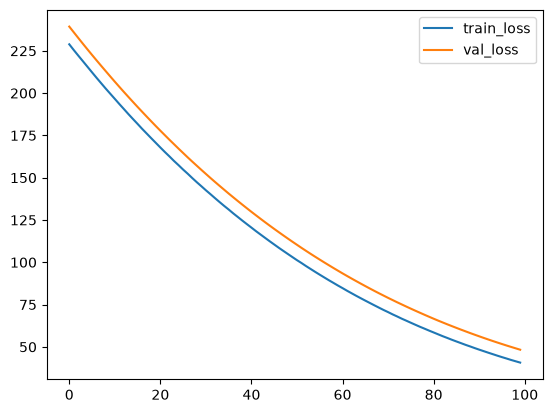

In [10]:
# 학습곡선
plt.plot(tr_loss_list, label= 'train_loss')
plt.plot(val_loss_list, label= 'val_loss')
plt.legend()
plt.show()